In [1]:
import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
import os
os.chdir(r"C:\Users\cebal\OneDrive\Documentos\Grandes Bases de Datos I")
cell_df = pd.read_csv("recursos_humanos (1).csv")
cell_df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [4]:
# Recodificación de las variables categóricas
cell_df = pd.get_dummies(cell_df, columns=["sales", "salary"], drop_first=True)
cell_df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,False,False,False,False,False,False,True,False,False,True,False
1,0.80,0.86,5,262,6,0,1,0,False,False,False,False,False,False,True,False,False,False,True
2,0.11,0.88,7,272,4,0,1,0,False,False,False,False,False,False,True,False,False,False,True
3,0.72,0.87,5,223,5,0,1,0,False,False,False,False,False,False,True,False,False,True,False
4,0.37,0.52,2,159,3,0,1,0,False,False,False,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,False,False,False,False,False,False,False,True,False,True,False
14995,0.37,0.48,2,160,3,0,1,0,False,False,False,False,False,False,False,True,False,True,False
14996,0.37,0.53,2,143,3,0,1,0,False,False,False,False,False,False,False,True,False,True,False
14997,0.11,0.96,6,280,4,0,1,0,False,False,False,False,False,False,False,True,False,True,False


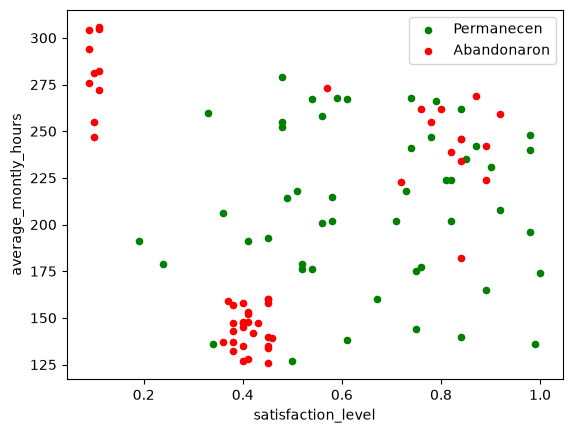

In [5]:
# Diagrama de dispersión
E = cell_df[cell_df["left"] == 0]
S = cell_df[cell_df["left"] == 1]
ax = E[0:50].plot(
    kind="scatter",
    x="satisfaction_level",
    y="average_montly_hours",
    color="green",
    label="Permanecen"
)
ax = S[0:50].plot(
    kind="scatter",
    x="satisfaction_level",
    y="average_montly_hours",
    color="red",
    label="Abandonaron",
    ax=ax
)
plt.show()

In [6]:
# Pre-Procesamiento de datos y selección
feature_df = cell_df.drop(["left"], axis=1)
X = np.asarray(feature_df)
X[0:5]

array([[0.38, 0.53, 2, 157, 3, 0, 0, False, False, False, False, False,
        False, True, False, False, True, False],
       [0.8, 0.86, 5, 262, 6, 0, 0, False, False, False, False, False,
        False, True, False, False, False, True],
       [0.11, 0.88, 7, 272, 4, 0, 0, False, False, False, False, False,
        False, True, False, False, False, True],
       [0.72, 0.87, 5, 223, 5, 0, 0, False, False, False, False, False,
        False, True, False, False, True, False],
       [0.37, 0.52, 2, 159, 3, 0, 0, False, False, False, False, False,
        False, True, False, False, True, False]], dtype=object)

In [7]:
# Eliminación de renglones no numéricos
cell_df.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales_RandD                 bool
sales_accounting            bool
sales_hr                    bool
sales_management            bool
sales_marketing             bool
sales_product_mng           bool
sales_sales                 bool
sales_support               bool
sales_technical             bool
salary_low                  bool
salary_medium               bool
dtype: object

In [8]:
# Selección de características
feature_df = cell_df.drop(["left"], axis=1)
X = np.asarray(feature_df)
X[0:5]

array([[0.38, 0.53, 2, 157, 3, 0, 0, False, False, False, False, False,
        False, True, False, False, True, False],
       [0.8, 0.86, 5, 262, 6, 0, 0, False, False, False, False, False,
        False, True, False, False, False, True],
       [0.11, 0.88, 7, 272, 4, 0, 0, False, False, False, False, False,
        False, True, False, False, False, True],
       [0.72, 0.87, 5, 223, 5, 0, 0, False, False, False, False, False,
        False, True, False, False, True, False],
       [0.37, 0.52, 2, 159, 3, 0, 0, False, False, False, False, False,
        False, True, False, False, True, False]], dtype=object)

In [9]:
# Variable objetivo
cell_df["left"] = cell_df["left"].astype("int")
y = np.asarray(cell_df["left"])
y[0:5]

array([1, 1, 1, 1, 1])

In [10]:
# Creación de grupos de entrenamiento y prueba
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=4
)
print("Grupo de entrenamiento", x_train.shape, y_train.shape)
print("Grupo de prueba", x_test.shape, y_test.shape)

Grupo de entrenamiento (11999, 18) (11999,)
Grupo de prueba (3000, 18) (3000,)


#  Modelacion con SVM Opciones de Kernel (Transformaciones):
Linear
Polynomial
Rdial Basis Function (RBF)
Sigmoid 

In [11]:
# Modelo SVM con kernel RBF
from sklearn import svm
clf = svm.SVC(kernel="rbf")
clf.fit(x_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [12]:
# Predicción para la base de prueba
yhat = clf.predict(x_test)
yhat[0:5]

array([0, 0, 0, 0, 0])

In [13]:
# Creación de matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x_test)
cm = confusion_matrix(y_test, yhat)
cm

array([[2287,    0],
       [ 666,   47]])

In [14]:
# Comparacion de valores realies y pronosticados
y_test

array([0, 1, 0, ..., 0, 1, 1], shape=(3000,))

In [16]:
yhat

array([0, 0, 0, ..., 0, 0, 0], shape=(3000,))

In [17]:
# Diferencia entre valores reales y pronosticados
z = y_test - yhat
z

array([0, 1, 0, ..., 0, 1, 1], shape=(3000,))

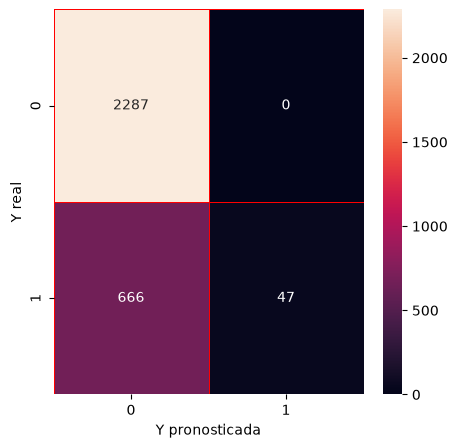

In [18]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm, annot=True, linewidths=0.5,
            linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("Y pronosticada")
plt.ylabel("Y real")
plt.show()

# Estadisticas de Desempeño

In [19]:
from sklearn.metrics import classification_report

cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.77      1.00      0.87      2287
           1       1.00      0.07      0.12       713

    accuracy                           0.78      3000
   macro avg       0.89      0.53      0.50      3000
weighted avg       0.83      0.78      0.69      3000



# Determinacion de niveles de precision
Precision = Porcentaje de predicciones correctas relativas al total de predicciones

In [20]:
PrecisionPermanece = cm[0,0] / (cm[0,0] + cm[1,0])
PrecisionPermanece

np.float64(0.7744666440907552)

In [21]:
PrecisionAbandona = cm[1,1] / (cm[1,1] + cm[0,1])
PrecisionAbandona

np.float64(1.0)

# Determinacion de Niveles de Recuperacion (Recall)
la recuperacion (recall) = Porcentaje de predicciones correctas relativas al total de valores reales

In [22]:
RecallPermanece = cm[0,0] / (cm[0,0] + cm[0,1])
RecallPermanece

np.float64(1.0)

In [23]:
RecallAbandona = cm[1,1] / (cm[1,0] + cm[1,1])
RecallAbandona

np.float64(0.06591865357643759)

# Determinacion del Score F1
F1 score = media armonica ponderada de la presicion y la recuperacion. Cuanto mas se acerque a 1, mejor sera el modelo
F1 Score = 2*(Precison * Recall)/(Precision + Recall)

In [24]:
F1Permanece = 2 * (PrecisionPermanece * RecallPermanece) / (PrecisionPermanece + RecallPermanece)
F1Permanece

np.float64(0.8729007633587785)

In [25]:
F1Abandona = 2 * (PrecisionAbandona * RecallAbandona) / (PrecisionAbandona + RecallAbandona)
F1Abandona

np.float64(0.12368421052631579)

# Determinacion de Soportes
Numero de observaciones que permanecen en forma real a cada clase posible (total por renglon)

In [26]:
SoportePermanece = cm[0,0] + cm[0,1]
SoportePermanece

np.int64(2287)

In [27]:
SoporteAbandona = cm[1,0] + cm[1,1]
SoporteAbandona

np.int64(713)

# Determinacion de la precision global
Accuracy = Porcentaje de predicciones correctas

In [29]:
Correctos = cm[0,0] + cm[1,1]
Incorrectos = cm[0,1] + cm[1,0]
PrecisionGlobal = Correctos / (Correctos + Incorrectos)
PrecisionGlobal

np.float64(0.778)

# Promedios Simples por Indicador (Macro Average)
Promedio simples por precision, recuperacion y f1-score

In [30]:
MacroAvgPrecision = (PrecisionPermanece + PrecisionAbandona) / 2
MacroAvgPrecision

np.float64(0.8872333220453776)

In [31]:
MacroAvgRecall = (RecallPermanece + RecallAbandona) / 2
MacroAvgRecall

np.float64(0.5329593267882188)

In [32]:
MacroF1Score = (F1Permanece + F1Abandona) / 2
MacroF1Score

np.float64(0.49829248694254713)

# Promedios ponderados por indicador (Weighed Average)
Promedios ponderados de acuerdo a soportes por indicador

In [35]:
PesoPermanece = SoportePermanece / (SoportePermanece + SoporteAbandona)
PesoAbandona = SoporteAbandona / (SoportePermanece + SoporteAbandona)

WAvgPrecision = PrecisionPermanece * PesoPermanece + PrecisionAbandona * PesoAbandona
WAvgPrecision

np.float64(0.8280684050118523)

In [36]:
WAvgRecall = RecallPermanece * PesoPermanece + RecallAbandona * PesoAbandona
WAvgRecall

np.float64(0.778)

In [37]:
WAvgF1Score = F1Permanece * PesoPermanece + F1Abandona * PesoAbandona
WAvgF1Score

np.float64(0.6948369626355966)

# Prueba de SVM con Kernel Lineal

In [ ]:
clf = svm.SVC(kernel='linear')
clf.fit(x_train, y_train)
yhat = clf.predict(x_test)

In [ ]:
# Matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x_test)
cm = confusion_matrix(y_test, yhat)
cm

In [ ]:
from sklearn.metrics import classification_report
# Importar iterools
cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
# np.set_printoptions(precision=2)
print(classification_report(y_test, yhat))

# Prueba de SVM con Kernel Polinomial

In [ ]:
clf = svm.SVC(kernel='poly')
clf.fit(x_train, y_train)
yhat = clf.predict(x_test)
# Matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x_test)
cm = confusion_matrix(y_test, yhat)
cm